# BÀI 6 — TRANSFER LEARNING CHO PHÂN LOẠI ẢNH VỚI PYTORCH

**Chủ đề:** Phân loại **Oxford Flowers-102** (102 lớp) bằng mô hình **ResNet18 pretrained ImageNet-1K**.    
**Môi trường bắt buộc:** **Google Colab GPU (CUDA)**. Chọn **Runtime → Change runtime type → T4 GPU**, sau đó **Runtime → Run all**.
> **Lưu ý đối chứng:** Scratch/Partial/Full chạy 5 epoch, Linear Probe chạy 25 epoch trên embeddings được cache.

### Kết quả học tập
1. Phân biệt **pretraining**, **transfer learning**, **feature extraction**, **linear probing**, **partial/full fine-tuning** và **training from scratch**.
2. Hiểu **source/target domain**, domain shift, negative transfer và giới hạn của pretrained weights.
3. Tiền xử lý ảnh đúng chuẩn ImageNet, thay classifier head và kiểm tra số tham số học được.
4. Áp dụng đóng băng lớp, quản lý BatchNorm, learning rate theo tầng, feature caching và checkpoint.
5. Đọc **validation loss / top-1 / macro-F1 / top-5**; chọn mô hình chỉ bằng validation và đánh giá test một lần.
6. Phân tích nhầm lẫn, ảnh sai và suy luận sau khi tải lại checkpoint.

**Nguồn dữ liệu:** https://www.robots.ox.ac.uk/~vgg/data/flowers/102/index.html  
**PyTorch transfer learning:** https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html  
**Preprocessing ResNet18:** https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html


## Nội dung thực hành

| Buổi | Nội dung trọng tâm | Kết quả cần nộp |
|---|---|---|
| 1 | Dataset khó, pretrained model, input normalization, thay head | Kiểm tra tensor / số tham số / chia dữ liệu |
| 2 | Từ đầu và **linear probing** với backbone đóng băng | Bảng loss, accuracy, macro-F1, learning curves |
| 3 | **Partial** và **full fine-tuning**, BatchNorm, learning rate theo tầng | So sánh 4 cách học trên validation |
| 4 | Test độc lập, dự đoán sai, checkpoint, thảo luận giới hạn | Bảng tổng kết và bài tập mở rộng |

**Quy tắc khoa học:** không xem test khi chỉnh mô hình; mọi nhận xét mang tính quan sát trên một lần chạy, không phải kết luận thống kê về ưu thế tuyệt đối.

## 0. Thiết lập và kiểm soát tái lập

- **Sử dụng CUDA:** Notebook cố định `DEVICE = torch.device("cuda:0")`.
- **Seed = 42:**
- **Thời lượng:** số epoch đã chạy trong output là `5/25/5/5` cho Scratch/Probe/Partial/Full.
- **Thư viện:** dùng PyTorch/torchvision đã có trong Colab;


### Cài thư viện cần thiết

Ô này kiểm tra và cài **một lần tất cả thư viện còn thiếu** trước khi import. PyTorch khá nặng nên lần cài đầu có thể mất vài phút. Bài gốc yêu cầu môi trường GPU CUDA; nếu chạy trên máy cá nhân, chọn đúng gói PyTorch theo GPU hoặc dùng Google Colab.


In [1]:
import importlib.util
import subprocess
import sys

required = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print('Cài trong một lần:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('Các thư viện đã sẵn sàng.')


Các thư viện đã sẵn sàng.


In [2]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224
NUM_CLASSES = 102
EPOCHS_SCRATCH = 5
EPOCHS_PROBE = 25
EPOCHS_PARTIAL = 5
EPOCHS_FULL = 5
PATIENCE = 4
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./bai6_transfer_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), "Bài 6 yêu cầu GPU CUDA: Runtime → Change runtime type → T4 GPU."
DEVICE = torch.device("cuda:0")
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1


def set_seed(seed: int = SEED) -> None:
    """Đặt seed cho các thư viện."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("Torch:", torch.__version__, "| Torchvision:", __import__("torchvision").__version__)
print("Thiết bị:", DEVICE, "| Seed:", SEED)
print("Thư mục lưu mô hình:", OUTPUT_DIR.resolve())


Torch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
Thiết bị: cuda:0 | Seed: 42
Thư mục lưu mô hình: /content/bai6_transfer_outputs


## 1. Dữ liệu Oxford Flowers-102 phù hợp cho transfer learning?

Oxford Flowers-102 có **102 loài hoa** với ảnh thực, bối cảnh, góc chụp, kích thước và ánh sáng đa dạng; nhiều loài có hình dạng/màu sắc rất giống nhau. Bản chia chính thức gồm **1.020 train (10/lớp)**, **1.020 validation (10/lớp)**, **6.149 test**.

**Khó khăn cốt lõi:** 10 ảnh/lớp là quá ít để kỳ vọng một CNN sâu học toàn bộ đặc trưng thị giác từ đầu trong vài epoch. Pretraining trên **ImageNet-1K** cung cấp các biểu diễn cạnh, kết cấu, hình dạng và mẫu thị giác hữu ích, nhưng **không bảo đảm** thắng trong mọi thiết lập.

| Khái niệm | Trong bài thực hành |
|---|---|
| **Source domain** | Ảnh màu thuộc ImageNet-1K |
| **Source task** | Phân loại 1.000 lớp ImageNet |
| **Target domain** | Ảnh hoa Oxford-102 |
| **Target task** | Phân loại 102 loài hoa |
| **Backbone** | ResNet18 giữ chức năng trích xuất đặc trưng |
| **Head** | Lớp `Linear(512, 102)` thay classifier `Linear(512, 1000)` |
| **Domain shift** | Khác nguồn ảnh, phân bố, nhãn, độ chi tiết |
| **Negative transfer** | Biểu diễn nguồn không phù hợp có thể làm mô hình đích kém đi |

**Dữ liệu học và pretrained model tải qua Internet ở Colab**.

## 2. Chuẩn hóa theo pretrained weights, Dataset và DataLoader

ResNet18 pretrained ImageNet sử dụng ảnh RGB, chuẩn hóa `mean=[0.485, 0.456, 0.406]`, `std=[0.229,0.224,0.225]`, và thường dùng crop 224×224. **Không lấy mean/std từ tập test để chuẩn hóa.**

- **Train:** `RandomResizedCrop`, lật ngang, ColorJitter nhẹ, ToTensor, Normalize.
- **Validation/Test:** biến đổi **deterministic** `Resize(256) → CenterCrop(224) → ToTensor → Normalize`.
- **Linear probe cached features:** train cũng dùng biến đổi deterministic để có một embedding nhất quán cho mỗi ảnh; nếu muốn augmentation nhiều epoch thì phải trích xuất embeddings mới ở mỗi epoch hoặc bỏ caching.
- Không áp dụng vertical flip bừa bãi, vì có thể làm đổi đặc điểm phân biệt một số lớp/đối tượng ở bộ khác.

In [3]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.72, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = WEIGHTS.transforms()  # Resize 256 + CenterCrop 224 + Normalize

flowers_train = datasets.Flowers102(DATA_DIR, split="train", download=True,
                                    transform=train_transform)
flowers_train_clean = datasets.Flowers102(DATA_DIR, split="train", download=False,
                                          transform=eval_transform)
flowers_val = datasets.Flowers102(DATA_DIR, split="val", download=False,
                                  transform=eval_transform)
assert len(flowers_train) == len(flowers_train_clean) == 1020
assert len(flowers_val) == 1020
assert len({label for _, label in flowers_train_clean}) == NUM_CLASSES
train_loader = DataLoader(flowers_train, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
train_clean_loader = DataLoader(flowers_train_clean, batch_size=BATCH_SIZE, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(flowers_val, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
print("Train:", len(flowers_train), "| Validation:", len(flowers_val), "| Số lớp:", NUM_CLASSES)
sample_images, sample_labels = next(iter(train_loader))
print("Một batch:", tuple(sample_images.shape), "| Nhãn:", tuple(sample_labels.shape))
assert sample_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)


100%|██████████| 345M/345M [00:17<00:00, 20.2MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.89MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 28.7MB/s]


Train: 1020 | Validation: 1020 | Số lớp: 102
Một batch: (32, 3, 224, 224) | Nhãn: (32,)


### Hướng dẫn đọc kết quả — Dữ liệu

Dòng `Train: 1020 | Validation: 1020 | Số lớp: 102` xác nhận đúng hai split được sử dụng khi phát triển mô hình. Batch `[32, 3, 224, 224]` gồm 32 ảnh RGB; `[32]` là 32 nhãn. Mọi lớp thuộc `0..101`.

### Phân tích kết quả thực tế

Output ghi **1.020 ảnh train và 1.020 ảnh validation**, tương đương **10 ảnh/lớp trong mỗi split**. Với 102 nhãn, đây là bài toán ít dữ liệu nhưng nhiều lớp. Test gồm 6.149 ảnh và chỉ được đưa vào pipeline sau khi chọn chiến lược từ validation.

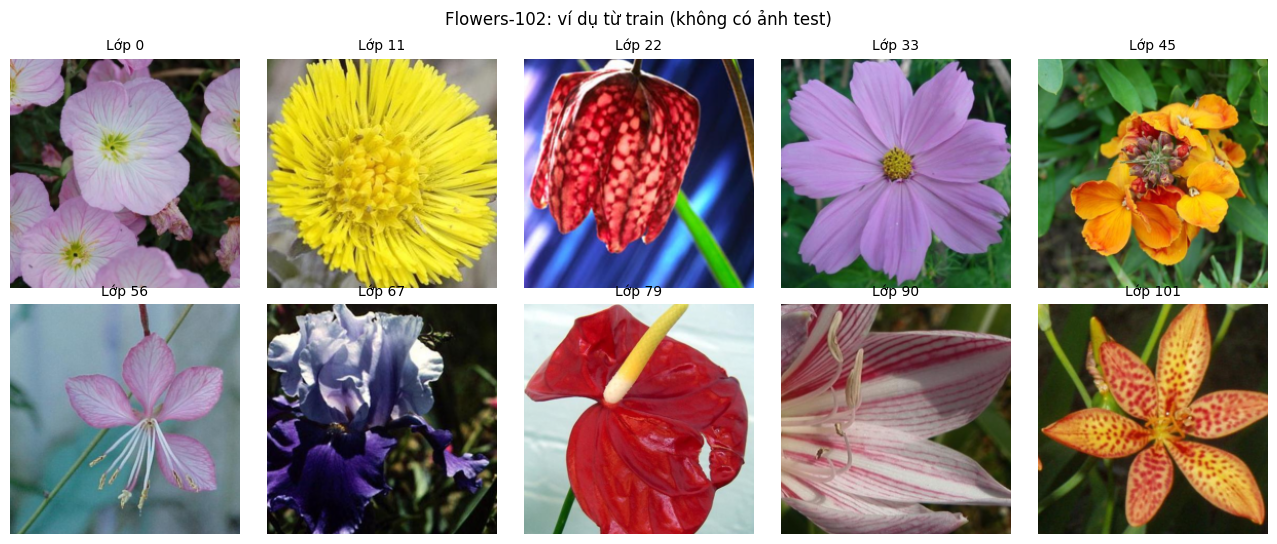

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for ax, idx in zip(axes.flat, np.linspace(0, len(flowers_train_clean) - 1, 10, dtype=int)):
    img, target = flowers_train_clean[int(idx)]
    arr = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(arr, 0.0, 1.0))
    ax.set_title(f"Lớp {target}", fontsize=10)
    ax.axis("off")
fig.suptitle("Flowers-102: ví dụ từ train (không có ảnh test)")
plt.tight_layout(); plt.show()


### Hướng dẫn đọc kết quả — Trực quan hóa

Hình hiển thị **10 ảnh lấy từ train** sau preprocessing xác định (không phải ảnh test). Xem sự thay đổi của màu sắc, kích thước bông hoa, góc nhìn và hậu cảnh; mỗi nhãn là mã lớp của Flowers-102.

## 3. Khám phá pretrained ResNet18: backbone, head và số tham số

**ResNet18** là CNN sâu có các residual connections giúp tối ưu hóa mạng sâu. Biểu diễn trước classifier có **512 chiều**.

- `weights=None`: khởi tạo hoàn toàn ngẫu nhiên (**scratch**).
- `weights=ResNet18_Weights.IMAGENET1K_V1`: nạp checkpoint học từ ImageNet (**pretrained**).
- Lệnh `model.fc = nn.Linear(model.fc.in_features, 102)` **thay classifier 1.000 lớp bằng classifier mới 102 lớp**.

**Sai lầm thường gặp:** chỉ thay `model.fc` nhưng quên tối ưu hóa đúng nhóm tham số; đặt `requires_grad=False` không đồng nghĩa `model.eval()`; đặc biệt BatchNorm vẫn có running statistics nếu không xử lý.

In [5]:
def count_parameters(model: nn.Module) -> dict[str, int]:
    """Đếm tổng số tham số và số tham số được phép học."""
    total = sum(param.numel() for param in model.parameters())
    trainable = sum(param.numel() for param in model.parameters() if param.requires_grad)
    return {"Total": total, "Trainable": trainable, "Frozen": total - trainable}


def build_resnet18(num_classes: int = NUM_CLASSES, pretrained: bool = True) -> nn.Module:
    """Khởi tạo ResNet18 và thay head theo số lớp đích."""
    model = models.resnet18(weights=WEIGHTS if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def configure_trainable(model: nn.Module, strategy: str) -> nn.Module:
    """Chọn lớp trainable: scratch, probe, partial, full."""
    if strategy not in ("scratch", "probe", "partial", "full"):
        raise ValueError(f"Chiến lược không được hỗ trợ: {strategy}")
    for parameter in model.parameters():
        parameter.requires_grad = strategy in ("scratch", "full")
    if strategy in ("probe", "partial"):
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    if strategy == "partial":
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
    return model


def set_training_mode(model: nn.Module, strategy: str) -> None:
    """Phân biệt `train()` với `requires_grad`; giữ Frozen BN ở eval."""
    model.train()
    if strategy in ("probe", "partial"):
        # Frozen BN: không cập nhật running_mean / running_var.
        # Với partial, các BN thuộc layer4 cũng giữ running stats ổn định khi ít dữ liệu.
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()


def build_optimizer(model: nn.Module, strategy: str) -> torch.optim.Optimizer:
    """Head học nhanh hơn backbone; tham số đóng băng không đưa vào optimizer."""
    if strategy == "scratch":
        return torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                 lr=1e-3, weight_decay=1e-4)
    if strategy == "probe":
        return torch.optim.AdamW(model.fc.parameters(), lr=3e-3, weight_decay=1e-3)
    if strategy == "partial":
        return torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    if strategy == "full":
        return torch.optim.AdamW([
            {"params": list(model.conv1.parameters()) + list(model.bn1.parameters()) +
                       list(model.layer1.parameters()) + list(model.layer2.parameters()), "lr": 1e-5},
            {"params": model.layer3.parameters(), "lr": 3e-5},
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    raise ValueError(strategy)


shape_demo = build_resnet18(num_classes=NUM_CLASSES, pretrained=False)
probe_demo = configure_trainable(copy.deepcopy(shape_demo), "probe")
partial_demo = configure_trainable(copy.deepcopy(shape_demo), "partial")
full_demo = configure_trainable(copy.deepcopy(shape_demo), "full")
display(pd.DataFrame([
    {"Chiến lược": "Scratch", **count_parameters(shape_demo)},
    {"Chiến lược": "Frozen + head", **count_parameters(probe_demo)},
    {"Chiến lược": "Layer4 + head", **count_parameters(partial_demo)},
    {"Chiến lược": "All layers", **count_parameters(full_demo)},
]))
assert probe_demo.fc.out_features == NUM_CLASSES
assert 0 < count_parameters(probe_demo)["Trainable"] < count_parameters(partial_demo)["Trainable"]
assert count_parameters(partial_demo)["Trainable"] < count_parameters(full_demo)["Trainable"]
del shape_demo, probe_demo, partial_demo, full_demo


,Chiến lược,Total,Trainable,Frozen
0,Scratch,11228838,11228838,0
1,Frozen + head,11228838,52326,11176512
2,Layer4 + head,11228838,8446054,2782784
3,All layers,11228838,11228838,0


### Hướng dẫn đọc kết quả — Số tham số

**Total** là tổng tham số của ResNet18 sau khi thay head; **Trainable** là số tham số được optimizer cập nhật; **Frozen** là phần còn lại. Việc đóng băng một tầng dùng `requires_grad=False`, khác với `model.eval()` (cách xử lý Dropout/BatchNorm).


### Phân tích kết quả thực tế — Số tham số

Bảng đã chạy ghi **11.228.838** tham số tổng cho cả bốn chiến lược. **Linear Probe** chỉ cập nhật **52.326** tham số. còn Scratch/Full FT cập nhật **11.228.838** tham số (**100%**). Đây là mức độ cập nhật khác nhau trên **cùng kiến trúc**.

### Kết luận — Số tham số

Đóng băng backbone không làm giảm số tham số của mô hình khi suy luận, nhưng giảm số trọng số cần cập nhật. Số tham số học được **không tự động** quyết định chất lượng hay thời gian thực tế: còn phụ thuộc forward/backward, cache embedding và số epoch.

## 4. Thiết kế hàm train/evaluate tái sử dụng

Quy trình: `zero_grad → forward → CrossEntropyLoss(logits, labels) → backward → optimizer.step`.

- `model.train()` cho train; `model.eval()` + `torch.inference_mode()` cho evaluate.
- **`CrossEntropyLoss` nhận logits**, không gọi `softmax` trước loss.
- Tổng hợp loss theo **số mẫu** (`loss.item() * batch_size`), không trung bình các trung bình batch khi batch cuối nhỏ.
- Chỉ dùng **validation loss** để chọn checkpoint / early stopping, báo cáo macro-F1 và top-5 như metrics bổ sung.
- Với tập ít mẫu, biến động giữa seed có thể lớn;

In [6]:
def evaluate(model: nn.Module, loader: DataLoader, num_classes: int = NUM_CLASSES) -> dict:
    """Đánh giá đầy đủ theo mẫu, trả về nhãn để tính macro-F1 và top-k."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, total, correct_1, correct_5 = 0.0, 0, 0, 0
    all_targets, all_preds = [], []
    with torch.inference_mode():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(inputs)
            total_loss += criterion(logits, targets).item()
            preds = logits.argmax(dim=1)
            correct_1 += int((preds == targets).sum())
            correct_5 += int((logits.topk(min(5, num_classes), dim=1).indices ==
                               targets.unsqueeze(1)).any(dim=1).sum())
            total += targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())
    assert total > 0
    return {"loss": total_loss / total, "accuracy": correct_1 / total,
            "top5": correct_5 / total,
            "macro_f1": f1_score(all_targets, all_preds, labels=list(range(num_classes)),
                                 average="macro", zero_division=0),
            "targets": np.asarray(all_targets), "preds": np.asarray(all_preds)}


def fit_model(name: str, model: nn.Module, train_data: DataLoader,
              val_data: DataLoader, strategy: str, epochs: int,
              num_classes: int = NUM_CLASSES) -> tuple[nn.Module, pd.DataFrame, dict]:
    """Huấn luyện, in từng epoch, lưu best checkpoint theo validation loss."""
    model = model.to(DEVICE)
    optimizer = build_optimizer(model, strategy)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    criterion = nn.CrossEntropyLoss()
    history, best_state = [], None
    best_loss, best_epoch, patience_count = float("inf"), 0, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        set_training_mode(model, strategy)
        total_loss, num_seen = 0.0, 0
        for inputs, targets in train_data:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(targets)
            num_seen += len(targets)
        val_metrics = evaluate(model, val_data, num_classes)
        epoch_record = {"epoch": epoch, "train_loss": total_loss / num_seen,
                        "val_loss": val_metrics["loss"], "val_acc": val_metrics["accuracy"],
                        "val_f1": val_metrics["macro_f1"], "val_top5": val_metrics["top5"]}
        history.append(epoch_record)
        print(f"[{name}] {epoch:02d}/{epochs:02d} | train_loss={epoch_record['train_loss']:.4f} "
              f"| val_loss={epoch_record['val_loss']:.4f} | val_acc={epoch_record['val_acc']:.2%} "
              f"| val_macroF1={epoch_record['val_f1']:.4f}")
        # Quy tắc nhất quán: mọi phương pháp chọn checkpoint bằng val_loss.
        if val_metrics["loss"] < best_loss - 1e-6:
            best_loss, best_epoch, patience_count = val_metrics["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1
        scheduler.step()
        if patience_count >= PATIENCE:
            print(f"[{name}] Early stopping tại epoch {epoch}.")
            break
    if best_state is None:
        raise RuntimeError("Không có checkpoint hợp lệ")
    model.load_state_dict(best_state)
    metrics = evaluate(model, val_data, num_classes)
    seconds = time.perf_counter() - start
    summary = {"Mô hình": name, "Best epoch": best_epoch,
               "Val loss": metrics["loss"], "Val accuracy": metrics["accuracy"],
               "Val macro-F1": metrics["macro_f1"], "Val top-5": metrics["top5"],
               "Thời gian (s)": round(seconds, 1),
               "Trainable": count_parameters(model)["Trainable"]}
    print(f"[{name}] BEST epoch={best_epoch}, val_loss={metrics['loss']:.4f}, "
          f"val_accuracy={metrics['accuracy']:.2%}")
    return model, pd.DataFrame(history), summary


def plot_histories(histories: dict[str, pd.DataFrame], title: str) -> None:
    """Trực quan hóa lịch sử trên train/validation của các phương pháp."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for name, frame in histories.items():
        axes[0].plot(frame.epoch, frame.val_acc, marker="o", label=name)
        axes[1].plot(frame.epoch, frame.train_loss, linestyle="--", alpha=0.5,
                     label=f"{name} train")
        axes[1].plot(frame.epoch, frame.val_loss, marker="o", label=f"{name} val")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy", ylim=(0, 1))
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy", title="Train loss / Val loss")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


### Hướng dẫn đọc kết quả — Hàm huấn luyện

- `train_loss`: cross-entropy trung bình trên ảnh train, có augmentation đối với Scratch/Partial/Full; Linear Probe học từ embedding cố định đã cache.
- `val_loss`, `val_acc`, `val_macroF1`, `val_top5`: đều tính trên validation dùng preprocessing xác định.
- Mỗi epoch được log độc lập. **Checkpoint tốt nhất được chọn theo `val_loss`**, không phải accuracy. Nếu `val_loss` không cải thiện qua số epoch cấu hình, early stopping có thể kích hoạt.
- Model được khôi phục từ `best_state` **trước khi** ghi bảng summary, so sánh và đánh giá test.

### Chú ý khi phân tích

Loss và accuracy đo hai khía cạnh khác nhau: loss nhạy với **mức xác suất gán cho nhãn thật**, còn top-1 chỉ xét nhãn đứng đầu. Vì vậy một mô hình có top-1 cao nhất **không nhất thiết** có validation loss thấp nhất. Đây chính là điểm quan trọng trong kết quả của bài.


## 5. Thí nghiệm A — ResNet18 **huấn luyện từ đầu** (baseline)

Khởi tạo `weights=None` rồi tối ưu hóa toàn bộ mạng. **Không coi 5 epoch là đủ cho scratch hội tụ**.

**Giả thuyết:** với 10 ảnh/lớp, scratch khó hình thành representation có khả năng tổng quát trong ngân sách nhỏ.

In [7]:
histories, fitted_models, summaries = {}, {}, {}
set_seed(SEED)
scratch_model = configure_trainable(build_resnet18(pretrained=False), "scratch")
scratch_model, histories["Scratch"], summaries["Scratch"] = fit_model(
    "Scratch", scratch_model, train_loader, val_loader,
    strategy="scratch", epochs=EPOCHS_SCRATCH)
fitted_models["Scratch"] = scratch_model.cpu()
display(pd.DataFrame([summaries["Scratch"]]).round(4))
del scratch_model
torch.cuda.empty_cache()


[Scratch] 01/05 | train_loss=4.6376 | val_loss=5.7485 | val_acc=5.49% | val_macroF1=0.0149
[Scratch] 02/05 | train_loss=3.8868 | val_loss=4.5255 | val_acc=7.06% | val_macroF1=0.0407
[Scratch] 03/05 | train_loss=3.6352 | val_loss=3.7117 | val_acc=11.47% | val_macroF1=0.0746
[Scratch] 04/05 | train_loss=3.3198 | val_loss=3.4137 | val_acc=16.18% | val_macroF1=0.1132
[Scratch] 05/05 | train_loss=2.9637 | val_loss=3.1578 | val_acc=21.27% | val_macroF1=0.1630
[Scratch] BEST epoch=5, val_loss=3.1578, val_accuracy=21.27%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Scratch,5,3.1578,0.2127,0.163,0.5275,81.8,11228838


### Hướng dẫn đọc kết quả — Thí nghiệm A (Scratch)

Xem sự tiến triển của `train_loss`, `val_loss`, `val_acc`, `val_macroF1` qua 5 epoch, sau đó đối chiếu bảng summary ở **best epoch theo validation loss**. Đối với 102 lớp, accuracy ngẫu nhiên cân bằng xấp xỉ **0,98%**;

### Phân tích kết quả thực tế — Thí nghiệm A

- `train_loss` giảm từ **4,6006 → 2,8519**, `val_loss` giảm từ **5,3901 → 3,0851**.
- `val_acc` tăng từ **4,80% → 24,51%**; `val_macroF1` từ **0,0090 → 0,2065**. `val_top5` cuối đạt **54,61%**.
- **Best epoch = 5/5**, với **11.228.838** tham số được học và thời gian huấn luyện ghi nhận **41,9 giây**. Loss và accuracy vẫn cải thiện ở epoch cuối, nên **không có cơ sở nói mô hình đã hội tụ**.

### Kết luận — Thí nghiệm A

Huấn luyện ResNet18 từ đầu đạt **24,51% validation accuracy** sau 5 epoch, kém xa các phương pháp bắt đầu từ pretrained weights trong cùng notebook. Điều này minh họa bất lợi của học biểu diễn thị giác từ đầu với chỉ 10 ảnh/lớp; **không có nghĩa ResNet18 scratch không thể đạt cao hơn nếu được huấn luyện lâu hơn hoặc dùng cấu hình khác**.

## 6. Thí nghiệm B — **Frozen feature extractor + linear probing**

**Ý tưởng:** giữ nguyên toàn bộ trọng số ImageNet của backbone, trích xuất vector 512 chiều và chỉ học một **linear classifier** 102 đầu ra. Đây là cách transfer learning nhanh, đặc biệt phù hợp dữ liệu ít.

**Tối ưu hóa đặc biệt:** với backbone đóng băng và biến đổi input **deterministic**, có thể cache embeddings một lần. Sau đó train head trên tensor 512 chiều.

**Lưu ý công bằng:** head dùng deterministic crop trong khi scratch/partial/full dùng augmentation; có thể xem đây là khác biệt pipeline có chủ đích, không phải một *ablation* chỉ thay đúng một biến. Để kiểm chứng thuần túy tác động pretrained, giữ transform và số lần cập nhật tương đương.

In [8]:
def extract_features(pretrained_model: nn.Module, loader: DataLoader) -> TensorDataset:
    """Trích xuất một vector đặc trưng cho mỗi ảnh; không tính gradient."""
    backbone = copy.deepcopy(pretrained_model)
    backbone.fc = nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    vectors, labels = [], []
    with torch.inference_mode():
        for images, targets in loader:
            features = backbone(images.to(DEVICE, non_blocking=True))
            vectors.append(features.cpu())
            labels.append(targets.clone())
    del backbone
    return TensorDataset(torch.cat(vectors), torch.cat(labels))


class LinearProbe(nn.Module):
    """Head tuyến tính dùng cho embeddings 512 chiều đã được cache."""
    def __init__(self, in_features: int = 512, out_features: int = NUM_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)


pretrained_probe = build_resnet18(pretrained=True)
# Có thể kiểm tra tài nguyên: 1020 x 512 số float32 ≈ 2 MB mỗi split.
cached_train = extract_features(pretrained_probe, train_clean_loader)
cached_val = extract_features(pretrained_probe, val_loader)
print("Cached train:", tuple(cached_train.tensors[0].shape),
      "| Cached val:", tuple(cached_val.tensors[0].shape))
probe_train_loader = DataLoader(cached_train, batch_size=128, shuffle=True)
probe_val_loader = DataLoader(cached_val, batch_size=256, shuffle=False)
set_seed(SEED)
probe_head = LinearProbe()
probe_head, histories["Linear probe"], summaries["Linear probe"] = fit_model(
    "Linear probe", probe_head, probe_train_loader, probe_val_loader,
    strategy="probe", epochs=EPOCHS_PROBE)
# Khi cần inference trên ảnh, ghép head đã học vào backbone pretrained.
pretrained_probe.fc.load_state_dict(probe_head.fc.cpu().state_dict())
fitted_models["Linear probe"] = configure_trainable(pretrained_probe.cpu(), "probe")
summaries["Linear probe"]["Trainable"] = count_parameters(fitted_models["Linear probe"])["Trainable"]
display(pd.DataFrame([summaries["Linear probe"]]).round(4))
del probe_head, cached_train, cached_val, pretrained_probe
torch.cuda.empty_cache()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 219MB/s]


Cached train: (1020, 512) | Cached val: (1020, 512)
[Linear probe] 01/25 | train_loss=4.5336 | val_loss=3.7540 | val_acc=23.53% | val_macroF1=0.1918
[Linear probe] 02/25 | train_loss=3.1316 | val_loss=2.7940 | val_acc=55.98% | val_macroF1=0.5193
[Linear probe] 03/25 | train_loss=2.1006 | val_loss=2.1581 | val_acc=66.76% | val_macroF1=0.6501
[Linear probe] 04/25 | train_loss=1.4595 | val_loss=1.7366 | val_acc=74.41% | val_macroF1=0.7342
[Linear probe] 05/25 | train_loss=1.0568 | val_loss=1.4748 | val_acc=77.45% | val_macroF1=0.7681
[Linear probe] 06/25 | train_loss=0.7972 | val_loss=1.3045 | val_acc=80.49% | val_macroF1=0.8013
[Linear probe] 07/25 | train_loss=0.6286 | val_loss=1.1839 | val_acc=81.27% | val_macroF1=0.8080
[Linear probe] 08/25 | train_loss=0.5175 | val_loss=1.1059 | val_acc=80.78% | val_macroF1=0.8085
[Linear probe] 09/25 | train_loss=0.4288 | val_loss=1.0426 | val_acc=82.75% | val_macroF1=0.8257
[Linear probe] 10/25 | train_loss=0.3756 | val_loss=0.9954 | val_acc=83.43%

,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Linear probe,25,0.8378,0.848,0.847,0.9608,0.7,52326


### Hướng dẫn đọc kết quả — Thí nghiệm B (Linear Probing)

`Cached train: (1020, 512)` và `Cached val: (1020, 512)` nghĩa là mỗi ảnh được mã hóa thành vector 512 chiều bởi backbone ImageNet đã đóng băng. Head tuyến tính học từ các vector này; `Best epoch` là epoch có **val_loss thấp nhất**.

### Phân tích kết quả thực tế — Thí nghiệm B

- Model đã tải **ResNet18 pretrained ImageNet-1K** (file weights ~44,7 MB); dữ liệu cache có kích thước **1.020 × 512** cho mỗi split train/validation.
- `val_acc` tăng từ **23,53%** (epoch 1) lên **84,80%** (epoch 25); `val_loss` giảm từ **3,7540 → 0,8378**; `val_macroF1` đạt **0,8470**, `val_top5` **96,08%**.
- So với Scratch 5 epoch, validation accuracy cao hơn **60,29 điểm phần trăm** (84,80% so với 24,51%). Chỉ **52.326 tham số (~0,47%)** được cập nhật.
- Thời gian ghu **0,7 giây** cho phần huấn luyện head **sau khi cache đặc trưng**; **không bao gồm thời gian tải weights và trích xuất embedding**, vì những thao tác này nằm ngoài bộ đếm của `fit_model`.

### Kết luận — Thí nghiệm B

Các biểu diễn học từ ImageNet đủ hữu ích để phân biệt 102 lớp hoa với một head tuyến tính nhỏ: **84,80% validation accuracy**, dù backbone không được cập nhật.

## 7. Thí nghiệm C — **Partial fine-tuning** (`layer4` + head)

Đóng băng `conv1`, `bn1`, `layer1..3`, mở **`layer4`** và head. So với linear probing, tầng cao được điều chỉnh để phân biệt các loại hoa gần giống nhau.

**BatchNorm:** chỉ `requires_grad=False` không khóa `running_mean/var`; ở dữ liệu ít, ta cố ý đặt **mọi BatchNorm ở `eval()`** trong lúc train partial. Các trọng số affine của BN thuộc `layer4` vẫn có thể cập nhật nếu `requires_grad=True`. Đây là một lựa chọn thiết kế, cần ghi rõ.

**Discriminative learning rates:** `layer4` dùng `1e-4`, head dùng `1e-3`; backbone pretrained thay đổi chậm hơn head mới.

In [9]:
set_seed(SEED)
partial_model = configure_trainable(build_resnet18(pretrained=True), "partial")
print("Số tham số partial:", count_parameters(partial_model))
partial_model, histories["Partial FT"], summaries["Partial FT"] = fit_model(
    "Partial FT", partial_model, train_loader, val_loader,
    strategy="partial", epochs=EPOCHS_PARTIAL)
fitted_models["Partial FT"] = partial_model.cpu()
display(pd.DataFrame([summaries["Partial FT"]]).round(4))
del partial_model
torch.cuda.empty_cache()


Số tham số partial: {'Total': 11228838, 'Trainable': 8446054, 'Frozen': 2782784}
[Partial FT] 01/05 | train_loss=4.5319 | val_loss=3.8512 | val_acc=18.04% | val_macroF1=0.1095
[Partial FT] 02/05 | train_loss=2.4463 | val_loss=1.6348 | val_acc=57.35% | val_macroF1=0.5575
[Partial FT] 03/05 | train_loss=0.6860 | val_loss=1.0144 | val_acc=73.04% | val_macroF1=0.7304
[Partial FT] 04/05 | train_loss=0.2241 | val_loss=0.7450 | val_acc=78.92% | val_macroF1=0.7871
[Partial FT] 05/05 | train_loss=0.0906 | val_loss=0.6609 | val_acc=81.86% | val_macroF1=0.8148
[Partial FT] BEST epoch=5, val_loss=0.6609, val_accuracy=81.86%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Partial FT,5,0.6609,0.8186,0.8148,0.9588,73.5,8446054


### Hướng dẫn đọc kết quả — Thí nghiệm C (Partial Fine-tuning)

Phương pháp mở `layer4` và classifier head, giữ các tầng trước đóng băng; các BatchNorm tiếp tục dùng running statistics đã có. Đọc đồng thời `val_loss`, `val_acc`, macro-F1 và số tham số được cập nhật, thay vì chỉ nhìn mỗi accuracy.

### Phân tích kết quả thực tế — Thí nghiệm C

- `train_loss` giảm **4,5317 → 0,0897** và `val_loss` giảm **3,8500 → 0,6618** sau 5 epoch; `val_acc` tăng từ **18,43% → 81,67%**.
- Summary ghi **val_macroF1 = 0,8128**, **val_top5 = 96,27%**, **best epoch = 5**, thời gian huấn luyện **39,5 giây** và **8.446.054** tham số được cập nhật.
- So với Linear Probe, Partial FT có **validation loss thấp hơn 0,1760** (0,6618 so với 0,8378) nhưng **top-1 accuracy thấp hơn 3,13 điểm phần trăm** (81,67% so với 84,80%). Điều này **không mâu thuẫn**, vì cross-entropy xét cả độ tự tin của dự đoán.
- Chênh lệch `train_loss` cuối (**0,0897**) và `val_loss` cuối (**0,6618**) cho thấy một khoảng cách train–validation đáng quan sát, nhưng `val_loss` vẫn giảm qua cả 5 epoch: **chưa đủ bằng chứng khẳng định overfitting đã bắt đầu tăng**.

### Kết luận — Thí nghiệm C

Partial FT có **validation loss thấp nhất trong bốn cấu hình (0,6618)**.

## 8. Thí nghiệm D — **Full fine-tuning** với learning rate theo tầng

Mở toàn bộ backbone và head. Dùng 4 nhóm learning rate để **tầng thấp thay đổi ít, tầng cao thay đổi nhiều**. Đây là full fine-tuning (khác **training from scratch** vì bắt đầu từ pretrained weights).

`AdamW` cho regularization, `CosineAnnealingLR` giảm learning rate. Vì bộ dữ liệu có ít mẫu, cần cân nhắc lịch mở dần tầng (*gradual unfreezing*) và early stopping. Có thể thử chiến lược **warm-start** từ head của linear probe ở bài tập mở rộng; ở đây head mới được khởi tạo ngẫu nhiên để phân biệt rõ cách huấn luyện.

In [10]:
set_seed(SEED)
full_model = configure_trainable(build_resnet18(pretrained=True), "full")
print("Learning rates (full):", [group["lr"] for group in build_optimizer(full_model, "full").param_groups])
full_model, histories["Full FT"], summaries["Full FT"] = fit_model(
    "Full FT", full_model, train_loader, val_loader,
    strategy="full", epochs=EPOCHS_FULL)
fitted_models["Full FT"] = full_model.cpu()
display(pd.DataFrame([summaries["Full FT"]]).round(4))
del full_model
torch.cuda.empty_cache()


Learning rates (full): [1e-05, 3e-05, 0.0001, 0.001]
[Full FT] 01/05 | train_loss=4.0761 | val_loss=2.5756 | val_acc=57.55% | val_macroF1=0.5486
[Full FT] 02/05 | train_loss=1.7307 | val_loss=1.4434 | val_acc=77.84% | val_macroF1=0.7615
[Full FT] 03/05 | train_loss=0.8150 | val_loss=1.0726 | val_acc=85.10% | val_macroF1=0.8504
[Full FT] 04/05 | train_loss=0.5004 | val_loss=0.9438 | val_acc=85.49% | val_macroF1=0.8512
[Full FT] 05/05 | train_loss=0.3845 | val_loss=0.9180 | val_acc=86.37% | val_macroF1=0.8615
[Full FT] BEST epoch=5, val_loss=0.9180, val_accuracy=86.37%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Full FT,5,0.918,0.8637,0.8615,0.9696,78.1,11228838


### Hướng dẫn đọc kết quả — Thí nghiệm D (Full Fine-tuning)

Cả backbone và head cùng được cập nhật nhưng có learning rate khác nhau: **`1e-5` (tầng thấp), `3e-5` (layer3), `1e-4` (layer4), `1e-3` (head)**.

### Phân tích kết quả thực tế — Thí nghiệm D

- Sau 5 epoch, `val_acc` tăng **57,55% → 86,18%** và `val_macroF1` đạt **0,8593**; `val_top5 = 96,96%`. `val_loss` giảm liên tục **2,5747 → 0,9176**.
- **86,18% là validation accuracy cao nhất** trong bốn cấu hình, hơn Linear Probe **1,38 điểm phần trăm** và hơn Partial FT **4,51 điểm phần trăm**.
- Dù top-1 cao nhất, `val_loss = 0,9176` vẫn **cao hơn Partial FT (0,6618)**. Chỉ từ loss tổng hợp không xác định được chính xác những ảnh nào đã bị dự đoán sai với độ tự tin cao; cần phân tích xác suất/hiệu chuẩn nếu muốn giải thích nguyên nhân.
- **11.228.838** tham số được cập nhật; thời gian huấn luyện ghi nhận **40,0 giây**. `val_loss` tiếp tục giảm ở epoch 5, nên chưa có bằng chứng mô hình đã đạt tối ưu.

### Kết luận — Thí nghiệm D

Full FT là cấu hình **tốt nhất về validation accuracy và macro-F1** trong thí nghiệm này.

## 9. Tổng hợp và so sánh kết quả **validation**

**Chọn mô hình trước khi mở test:** xếp theo `Val loss` tăng dần; khi bằng nhau, xếp theo `Val macro-F1` giảm dần. Cột thời gian của linear probe chỉ đo huấn luyện head, chưa tính thời gian cache embeddings, nên **không so sánh tổng chi phí trực tiếp**.

Một so sánh đầy đủ cần: ngân sách compute tương đương, nhiều seed, cùng chính sách augmentation và tuning riêng cho scratch.

,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Partial FT,5,0.6609,0.8186,0.8148,0.9588,73.5,8446054
1,Linear probe,25,0.8378,0.8480,0.8470,0.9608,0.7,52326
2,Full FT,5,0.9180,0.8637,0.8615,0.9696,78.1,11228838
3,Scratch,5,3.1578,0.2127,0.1630,0.5275,81.8,11228838


Mô hình được chọn CHỈ từ validation: Partial FT


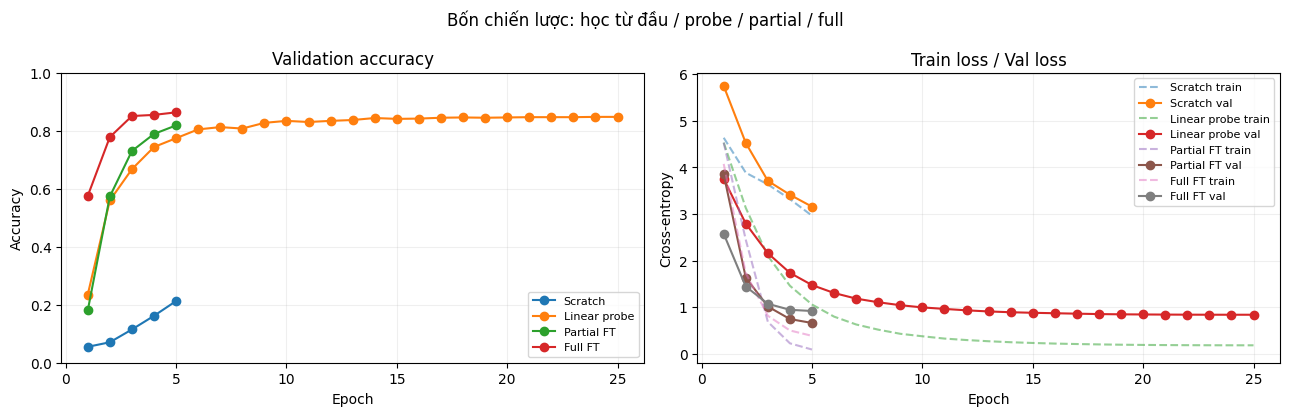

In [11]:
comparison = pd.DataFrame(summaries.values()).sort_values(
    ["Val loss", "Val macro-F1"], ascending=[True, False]).reset_index(drop=True)
display(comparison.round(4))
selected_name = str(comparison.iloc[0]["Mô hình"])
best_model = fitted_models[selected_name].to(DEVICE).eval()
print("Mô hình được chọn CHỈ từ validation:", selected_name)
plot_histories(histories, "Bốn chiến lược: học từ đầu / probe / partial / full")
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)


### Hướng dẫn đọc kết quả — Bảng so sánh validation

Bảng xếp theo **`Val loss` tăng dần**, khi bằng nhau mới dùng `Val macro-F1` giảm dần. `Best epoch` là checkpoint tối ưu theo loss trong thời lượng huấn luyện của từng phương pháp. **Chỉ mô hình đứng đầu bảng** được đánh giá trên test.

| Phương pháp | Best epoch | Val loss ↓ | Val accuracy ↑ | Val macro-F1 ↑ | Val top-5 ↑ |
|---|---:|---:|---:|---:|---:|
| **Partial FT** | 5 | **0,6618** | 81,67% | 0,8128 | 96,27% |
| Linear Probe | 25 | 0,8378 | 84,80% | 0,8470 | 96,08% |
| Full FT | 5 | 0,9176 | **86,18%** | **0,8593** | **96,96%** |
| Scratch | 5 | 3,0851 | 24,51% | 0,2065 | 54,61% |

### Phân tích kết quả thực tế — Bảng so sánh

- **Pretrained nổi trội so với đối chứng ngắn hạn:** ba cấu hình dùng ImageNet đạt **81,67–86,18%** validation accuracy, so với **24,51%** của Scratch.
- **Xếp hạng phụ thuộc metric:** Partial FT đứng đầu về **loss (0,6618)**; Full FT đứng đầu về **top-1 (86,18%)**, macro-F1 (**0,8593**) và top-5 (**96,96%**).
- **Thời gian huấn luyện hiển thị:** Scratch **41,9 s**, Partial **39,5 s**, Full **40,0 s**, Probe **0,7 s**. Probe chỉ tính giai đoạn học head sau khi trích xuất đặc trưng, vì vậy các số này **chưa phải so sánh công bằng tổng chi phí**.
- **Giới hạn:** một seed, số epoch không bằng nhau (Probe 25, các phương pháp khác 5), chưa có lặp lại và chưa có tìm kiếm siêu tham số. Không suy rộng kết luận thành thứ hạng tối ưu cho mọi dữ liệu.

### Kết luận — Lựa chọn mô hình

**Chọn `Partial FT` để đánh giá test**, do validation loss **0,6618** là nhỏ nhất dựa trên kết quả.

## 10. **Đánh giá test đúng một lần** và phân tích sai số

Test chính thức có 6.149 ảnh, dùng để **ước lượng hiệu quả ngoài mẫu sau khi chọn mô hình bằng validation**. Không dùng kết quả test để quay lại chọn hyperparameter. Macro-F1 trên test không nhất thiết trùng accuracy vì số lượng ảnh/lớp khác nhau.

In [12]:
flowers_test = datasets.Flowers102(DATA_DIR, split="test", download=False,
                                   transform=eval_transform)
assert len(flowers_test) == 6149
test_loader = DataLoader(flowers_test, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
test_metrics = evaluate(best_model, test_loader, NUM_CLASSES)
test_report = pd.DataFrame([{
    "Selected model": selected_name,
    "Test loss": test_metrics["loss"],
    "Test top-1 accuracy": test_metrics["accuracy"],
    "Test macro-F1": test_metrics["macro_f1"],
    "Test top-5 accuracy": test_metrics["top5"],
    "N test": len(flowers_test),
}])
display(test_report.round(4))
test_report.to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)


,Selected model,Test loss,Test top-1 accuracy,Test macro-F1,Test top-5 accuracy,N test
0,Partial FT,0.7038,0.8092,0.8058,0.9515,6149


### Hướng dẫn đọc kết quả — TEST

Top-1 accuracy là tỷ lệ ảnh có nhãn dự đoán đứng đầu trùng nhãn thật; top-5 là tỷ lệ nhãn thật xuất hiện trong 5 nhãn dự đoán có điểm cao nhất. Macro-F1 tính F1 trung bình không trọng số qua 102 lớp; `Test loss` là cross-entropy trung bình trên 6.149 ảnh chưa dùng để phát triển mô hình.

### Phân tích kết quả thực tế — TEST

Mô hình **Partial FT** được chọn từ validation đạt **test loss 0,7029**, **top-1 accuracy 81,04%**, **macro-F1 0,8060**, **top-5 accuracy 95,14%** trên **6.149 ảnh test**.

- So với validation của cùng mô hình: accuracy giảm **0,63 điểm phần trăm** (81,67% → 81,04%) và macro-F1 giảm **0,0068** (0,8128 → 0,8060); test loss tăng **0,0411** (0,6618 → 0,7029).
- Khoảng cách nhỏ trong lượt chạy này cho thấy hiệu năng trên test tương đối gần validation, **không chứng minh mô hình sẽ ổn định trên mọi tập ảnh hoặc phân bố khác**.
- Top-5 **95,14%** cao hơn top-1 **81,04%**, cho thấy nhiều trường hợp mô hình không chọn đúng nhãn đứng đầu nhưng nhãn thật vẫn có mặt trong 5 lựa chọn đầu.

### Kết luận — TEST

**Kết quả trên test: Partial FT, test accuracy 81,04%, macro-F1 0,8060, top-5 95,14%.**

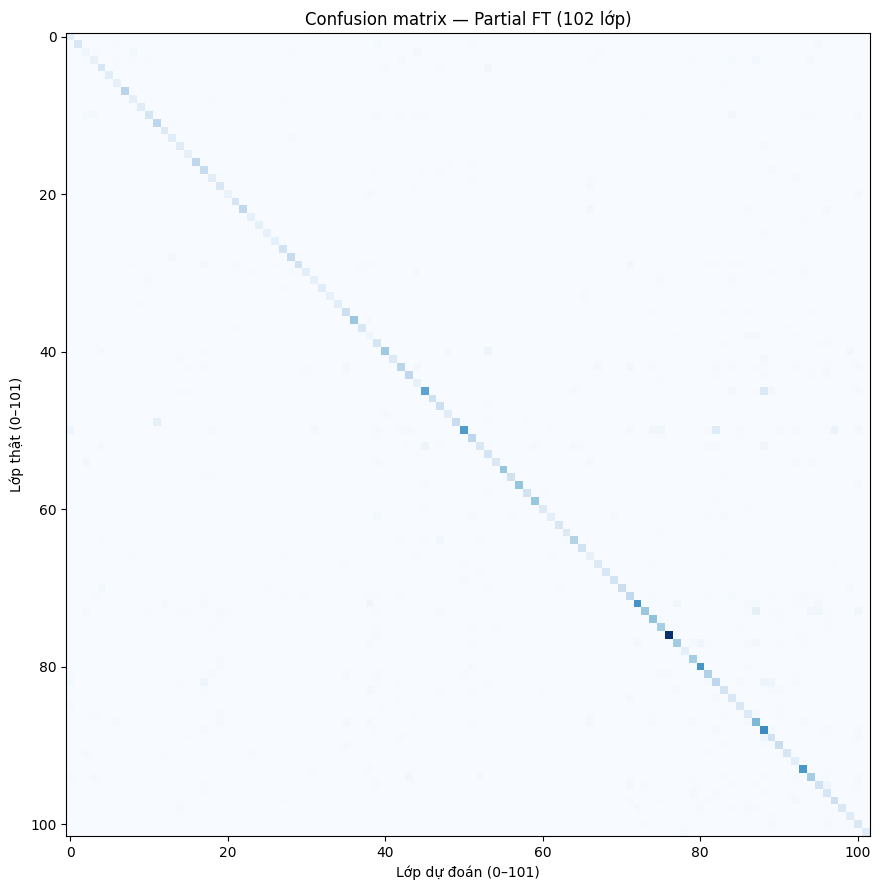

10 lớp có F1 thấp nhất:


,precision,recall,f1-score,support
Flower 002,0.250,0.400,0.308,20.0
Flower 038,0.257,0.429,0.321,21.0
Flower 003,0.552,0.444,0.492,36.0
Flower 066,0.447,0.773,0.567,22.0
Flower 082,0.590,0.559,0.574,111.0
Flower 052,0.842,0.438,0.577,73.0
Flower 100,0.457,0.842,0.593,38.0
Flower 096,0.486,0.761,0.593,46.0
Flower 044,0.472,0.850,0.607,20.0
Flower 092,0.471,0.923,0.623,26.0


In [13]:
label_names = [f"Flower {i:03d}" for i in range(NUM_CLASSES)]
cm = confusion_matrix(test_metrics["targets"], test_metrics["preds"],
                      labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set(xlabel="Lớp dự đoán (0–101)", ylabel="Lớp thật (0–101)",
       title=f"Confusion matrix — {selected_name} (102 lớp)")
plt.tight_layout(); plt.show()
class_report = classification_report(
    test_metrics["targets"], test_metrics["preds"],
    labels=np.arange(NUM_CLASSES), target_names=label_names,
    zero_division=0, output_dict=True)
class_table = pd.DataFrame(class_report).T.iloc[:NUM_CLASSES]
print("10 lớp có F1 thấp nhất:")
display(class_table.sort_values("f1-score").head(10).round(3))
class_table.to_csv(OUTPUT_DIR / "test_per_class_metrics.csv")


### Hướng dẫn đọc kết quả — Ma trận nhầm lẫn và bảng theo lớp

Đường chéo của ma trận 102×102 biểu diễn số ảnh dự đoán đúng; các ô ngoài đường chéo là nhầm lẫn. Với 102 lớp, bảng **10 lớp có F1 thấp nhất** giúp xác định nhóm cần xem lại. `support` là số ảnh thật của mỗi lớp trên test.

### Phân tích kết quả thực tế — Theo từng lớp

Các lớp gặp khó khăn nhất theo output là **Flower 002** (`F1 = 0,275`, `precision = 0,226`, `recall = 0,350`, `support = 20`) và **Flower 038** (`F1 = 0,316`, `precision = 0,250`, `recall = 0,429`, `support = 21`). Các lớp tiếp theo trong bảng gồm **Flower 003** (`0,485`), **Flower 066** (`0,557`), **Flower 082** (`0,562`).

Đáng chú ý, **Flower 092** có `recall = 0,923` nhưng `precision = 0,462` (F1 **0,615**, support **26**): mô hình nhận ra phần lớn ảnh thật của lớp này, song nhiều dự đoán đưa vào lớp 092 lại không đúng. Ngược lại, **Flower 052** có `precision = 0,865` nhưng `recall = 0,438` (F1 **0,582**, support **73**), biểu hiện mẫu lỗi khác. Chưa có bằng chứng từ bảng để kết luận nguyên nhân là màu, hình dạng hay lỗi nhãn.

### Kết luận — Theo từng lớp

Accuracy chung **81,04%** không thể hiện sự chênh lệch hiệu quả giữa 102 lớp. Nên kết hợp macro-F1, precision/recall, support và ảnh cụ thể khi phân tích lỗi;

Tổng ảnh dự đoán sai: 1173 / 6149


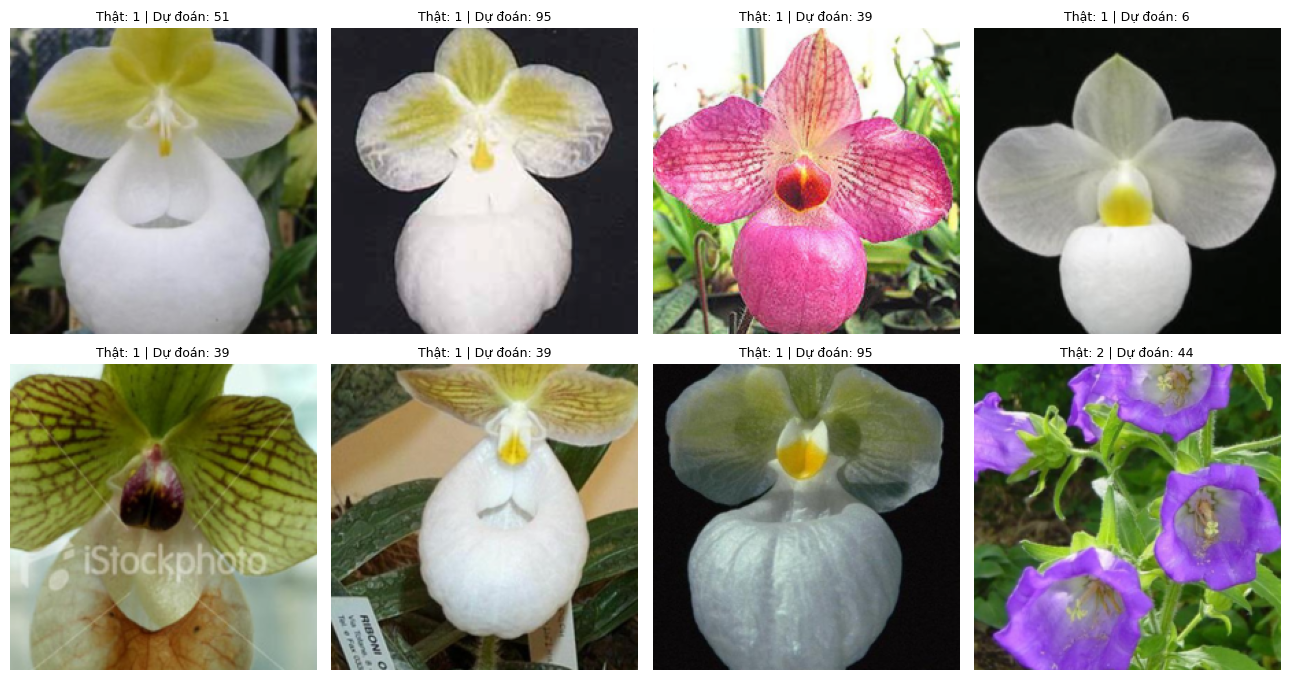

In [14]:
mistakes = np.where(test_metrics["targets"] != test_metrics["preds"])[0]
print("Tổng ảnh dự đoán sai:", len(mistakes), "/", len(flowers_test))
if len(mistakes) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, idx in zip(axes.flat, mistakes[:8]):
        tensor, true_label = flowers_test[int(idx)]
        arr = tensor.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(arr, 0, 1))
        ax.set_title(f"Thật: {true_label} | Dự đoán: {test_metrics['preds'][idx]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()


### Hướng dẫn đọc kết quả — Ảnh dự đoán sai

8 hình hiển thị là **8 ảnh sai đầu tiên theo thứ tự test**, mỗi ảnh có nhãn thật và nhãn dự đoán dạng ID. Trước khi xem ảnh, cần hoàn tác phép Normalize để hiển thị màu chính xác.

### Phân tích kết quả thực tế — Ảnh sai

Có **1.166 ảnh dự đoán sai trên 6.149 ảnh test**, tức khoảng **18,96%**; có **4.983 ảnh đúng**, khớp với test accuracy **81,04%**.

Từ những caption nhãn dạng số, chưa đủ cơ sở để khẳng định sai do hoa bị che, màu sắc giống nhau, hậu cảnh hay nhãn sai. Nếu muốn phân tích nguyên nhân, cần đối chiếu thêm nhiều ví dụ và nhãn/tên lớp chính thức.

### Kết luận — Ảnh sai

Mô hình vẫn sai gần **1/5 ảnh test**, dù top-5 cao hơn nhiều top-1. Một báo cáo đầy đủ cần đi từ **tỷ lệ sai tổng thể → lớp có F1 thấp → ảnh minh họa → giả thuyết nguyên nhân có kiểm chứng**, thay vì đưa ra giải thích trực giác không có dữ liệu hỗ trợ.

## 11. Lưu/tải checkpoint và suy luận một ảnh

Chỉ lưu **mô hình tốt nhất chọn bằng validation**; đóng gói trọng số, tên kiến trúc, số lớp, preprocessing và thông tin lựa chọn để có thể tái tạo inference. Tải bằng `weights_only=True` (chỉ tải từ nguồn tin cậy).

In [15]:
checkpoint_path = OUTPUT_DIR / "flowers102_best_resnet18.pt"
# Lưu dict chỉ gồm tensor và dữ liệu cơ bản, tương thích `weights_only=True`.
torch.save({
    "architecture": "resnet18", "num_classes": NUM_CLASSES,
    "selected_strategy": selected_name, "state_dict": {
        key: value.detach().cpu() for key, value in best_model.state_dict().items()
    },
    "image_size": IMAGE_SIZE, "normalization_mean": MEAN,
    "normalization_std": STD, "val_loss": float(comparison.iloc[0]["Val loss"]),
}, checkpoint_path)
payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored_model = build_resnet18(num_classes=payload["num_classes"], pretrained=False)
restored_model.load_state_dict(payload["state_dict"])
restored_model = restored_model.to(DEVICE).eval()
example_tensor, example_target = flowers_test[0]
with torch.inference_mode():
    before = best_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
    after = restored_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
assert torch.allclose(before, after, atol=1e-5, rtol=1e-5)
probabilities = after.softmax(dim=1)[0]
values, indices = probabilities.topk(5)
display(pd.DataFrame({"Lớp dự đoán": indices.tolist(),
                      "Xác suất": values.tolist()}))
print("Checkpoint:", checkpoint_path, "| Kích thước (MB):",
      round(checkpoint_path.stat().st_size / (1024 ** 2), 1))
print("Reload khớp logits:", bool(torch.allclose(before, after, atol=1e-5, rtol=1e-5)))


,Lớp dự đoán,Xác suất
0,0,0.796448
1,92,0.072744
2,66,0.036728
3,50,0.023863
4,97,0.021634


Checkpoint: bai6_transfer_outputs/flowers102_best_resnet18.pt | Kích thước (MB): 42.9
Reload khớp logits: True


Checkpoint lưu kiến trúc, 102 lớp, trọng số, chiến lược đã chọn, preprocessing và `val_loss`. `torch.allclose()` đối chiếu logits trên cùng ảnh trước/sau khi tải lại. Top-5 softmax cộng lại **không bắt buộc bằng 1**, vì còn 97 lớp khác.

Checkpoint có thể được tải lại để suy luận mà không cần huấn luyện lại. Khi dùng ở môi trường khác, phải giữ đúng preprocessing, cách ánh xạ chỉ số lớp và điều kiện sử dụng pretrained weights. **Một ảnh suy luận không thay thế được bộ đánh giá test.**

## Kết luận chung — Bài 6: Transfer Learning trên Flowers-102

**Bốn chiến lược cho kết quả rất khác nhau trong cùng lượt chạy đã lưu:**

1. **Scratch** (5 epoch) đạt **24,51%** validation accuracy: trong ngân sách huấn luyện ngắn và dữ liệu ít, việc học toàn bộ biểu diễn từ đầu chưa hiệu quả.
2. **Linear Probe** (25 epoch) đạt **84,80%** validation accuracy trong khi chỉ học **52.326** tham số: pretrained ImageNet cung cấp đặc trưng phù hợp đáng kể với bài toán hoa.
3. **Partial FT** đạt **validation loss thấp nhất 0,6618**, dù validation accuracy chỉ **81,67%**: được chọn đúng theo tiêu chí đã xác định.
4. **Full FT** có **validation accuracy cao nhất 86,18%** và macro-F1 **0,8593**, nhưng không có loss thấp nhất.

**Kết quả test cho mô hình được chọn (Partial FT):** accuracy **81,04%**, macro-F1 **0,8060**, top-5 **95,14%** trên **6.149 ảnh**, trong đó **1.166 ảnh bị phân loại sai**.

**Bài học phương pháp:**

- **Pretrained weights** giúp đáng kể trong lượt chạy này, nhưng Scratch được thử 5 epoch còn Probe 25 epoch nên không diễn giải đây là kết luận tuyệt đối cho mọi ngân sách.
- **Loss không đồng nghĩa accuracy**: lựa chọn mô hình phải dựa trên **một tiêu chí validation công bố trước**, không chọn lại sau khi thấy kết quả test.
- **Frozen feature extractor** có thể rất hiệu quả với dữ liệu ít; fine-tuning cần cân đối learning rate, số lớp mở và rủi ro overfitting/negative transfer.
- **Một seed không đủ chứng minh ưu thế ổn định**: ở phần bài tập, nên đánh giá đa seed, cân đối epoch/tổng thời gian và thí nghiệm trên backbone khác.

## 12. Các kiến thức mở rộng cần biết

| Chủ đề | Ý nghĩa | Quy tắc thực hành |
|---|---|---|
| **Linear probing** | Train head, giữ nguyên embeddings | Có thể cache, không cập nhật backbone |
| **Partial fine-tuning** | Điều chỉnh tầng cao theo domain đích | Head có LR lớn hơn layer4, quản lý BN |
| **Full fine-tuning** | Cập nhật toàn mạng từ pretrained | LR thấp cho tầng thấp, thường cần early stopping |
| **Gradual unfreezing** | Mở head → layer4 → layer3… | Có thể giảm shock gradient; cần thí nghiệm riêng |
| **Warm-start head** | Khởi tạo head từ linear probe | Tránh head ngẫu nhiên làm nhiễu pretrained features |
| **Discriminative LR** | LR theo nhóm layer | Không áp dụng một LR lớn cho mọi layer pretrained |
| **BatchNorm freeze** | Khóa running statistics trên dữ liệu ít | `eval()` khác `requires_grad=False` |
| **ImageNet normalization** | Đưa dữ liệu vào phân bố giống lúc pretrain | Dùng `weights.transforms()` khi eval/inference |
| **Data augmentation** | Tăng biến thiên train | Không augmentation ngẫu nhiên ở val/test |
| **Domain shift / negative transfer** | Khác dữ liệu nguồn–đích, hiệu ứng có thể âm | Không ngầm giả định pretrained luôn tốt |
| **Catastrophic forgetting** | Mất representation hữu ích sau cập nhật mạnh | LR nhỏ/early stopping/regularization |
| **Data leakage** | Trộn test vào tuning gây lạc quan giả | Chỉ dùng test sau khi chọn mô hình |
| **Compute–quality tradeoff** | Frozen head rẻ hơn toàn mạng | Tính cả chi phí trích xuất feature |
| **Modern pretrained architectures** | EfficientNet, ConvNeXt, ViT, Swin | Đổi transforms/head/điều kiện train đúng kiến trúc |

### Ví dụ đổi backbone (tham khảo, không đưa vào so sánh mặc định)

```python
# Nếu muốn EfficientNet-B0:
# weights = models.EfficientNet_B0_Weights.DEFAULT
# model = models.efficientnet_b0(weights=weights)
# model.classifier[1] = nn.Linear(model.classifier[1].in_features, 102)
# eval_transform = weights.transforms()
```

## 13. Bài tập dành cho sinh viên
Huấn luyện mô hình cho bộ dữ liệu FGVC-Aircraft(https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/?utm_source=chatgpt.com) sử dụng mô hình pretrained EfficientNet-B0.


**Tài liệu đọc:** [PyTorch transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html), [Oxford Flowers-102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/index.html), [Torchvision ResNet18 weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).

### Lời giải — Huấn luyện EfficientNet-B0 trên FGVC-Aircraft

Phần dưới đây hoàn thành yêu cầu bài 13 bằng **transfer learning**: thay classifier của EfficientNet-B0 pretrained ImageNet thành 100 lớp biến thể máy bay, fine-tune trên train, chọn checkpoint bằng validation rồi đánh giá test.

> Chạy các ô bên dưới theo thứ tự. Cần kết nối Internet ở lần đầu để tải bộ dữ liệu và trọng số pretrained. Nên dùng GPU Colab. Phần gốc phía trên được giữ nguyên.



#### 13.1. Cấu hình và tải dữ liệu


In [16]:
import copy, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from torchvision.models import EfficientNet_B0_Weights
from sklearn.metrics import f1_score, classification_report, confusion_matrix

AIRCRAFT_SEED = 42
AIRCRAFT_BATCH_SIZE = 32
AIRCRAFT_EPOCHS = 8
AIRCRAFT_PATIENCE = 3
AIRCRAFT_NUM_WORKERS = 4
AIRCRAFT_DATA_DIR = Path('./data')
AIRCRAFT_OUTPUT_DIR = Path('./fgvc_aircraft_outputs')
AIRCRAFT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AIRCRAFT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AIRCRAFT_NUM_CLASSES = 100

random.seed(AIRCRAFT_SEED)
np.random.seed(AIRCRAFT_SEED)
torch.manual_seed(AIRCRAFT_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(AIRCRAFT_SEED)
print('Thiết bị:', AIRCRAFT_DEVICE, '| PyTorch:', torch.__version__)
if AIRCRAFT_DEVICE.type != 'cuda':
    print('Cảnh báo: đang chạy CPU; hãy chọn GPU trong Colab để giảm thời gian huấn luyện.')
print('Thư mục lưu checkpoint:', AIRCRAFT_OUTPUT_DIR.resolve())


Thiết bị: cuda | PyTorch: 2.14.1+cu130
Thư mục lưu checkpoint: /content/fgvc_aircraft_outputs


FGVC-Aircraft có nhãn ở nhiều mức chi tiết. Đề bài phân loại biến thể, vì vậy chọn `annotation_level="variant"` (100 lớp). Dùng split `train` để cập nhật trọng số, `val` để chọn mô hình và `test` cho đánh giá cuối.


In [17]:
AIRCRAFT_WEIGHTS = EfficientNet_B0_Weights.DEFAULT
AIRCRAFT_IMAGE_SIZE = 224
AIRCRAFT_MEAN = (0.485, 0.456, 0.406)
AIRCRAFT_STD = (0.229, 0.224, 0.225)
aircraft_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(AIRCRAFT_IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(AIRCRAFT_MEAN, AIRCRAFT_STD),
])
aircraft_eval_transform = AIRCRAFT_WEIGHTS.transforms()

aircraft_train = datasets.FGVCAircraft(AIRCRAFT_DATA_DIR, split='train', annotation_level='variant', download=True, transform=aircraft_train_transform)
aircraft_val = datasets.FGVCAircraft(AIRCRAFT_DATA_DIR, split='val', annotation_level='variant', download=True, transform=aircraft_eval_transform)
aircraft_test = datasets.FGVCAircraft(AIRCRAFT_DATA_DIR, split='test', annotation_level='variant', download=True, transform=aircraft_eval_transform)
aircraft_classes = aircraft_train.classes
assert len(aircraft_classes) == AIRCRAFT_NUM_CLASSES, f'Có {len(aircraft_classes)} lớp, cần 100 lớp variant.'

aircraft_train_loader = DataLoader(aircraft_train, batch_size=AIRCRAFT_BATCH_SIZE, shuffle=True, num_workers=AIRCRAFT_NUM_WORKERS, pin_memory=(AIRCRAFT_DEVICE.type=='cuda'), persistent_workers=True)
aircraft_val_loader = DataLoader(aircraft_val, batch_size=AIRCRAFT_BATCH_SIZE, shuffle=False, num_workers=AIRCRAFT_NUM_WORKERS, pin_memory=(AIRCRAFT_DEVICE.type=='cuda'), persistent_workers=True)
aircraft_test_loader = DataLoader(aircraft_test, batch_size=AIRCRAFT_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=(AIRCRAFT_DEVICE.type=='cuda'))
print(f'Train: {len(aircraft_train):,} | Validation: {len(aircraft_val):,} | Test: {len(aircraft_test):,} | Số lớp: {len(aircraft_classes)}')
xb, yb = next(iter(aircraft_train_loader))
print('Kích thước batch ảnh:', tuple(xb.shape), '| nhãn:', tuple(yb.shape))




100%|██████████| 2.75G/2.75G [02:37<00:00, 17.5MB/s]


Train: 3,334 | Validation: 3,333 | Test: 3,333 | Số lớp: 100


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Kích thước batch ảnh: (32, 3, 224, 224) | nhãn: (32,)


#### Xem thử ảnh FGVC-Aircraft

Ô sau hiển thị 8 ảnh từ train sau augmentation, kèm tên biến thể máy bay.


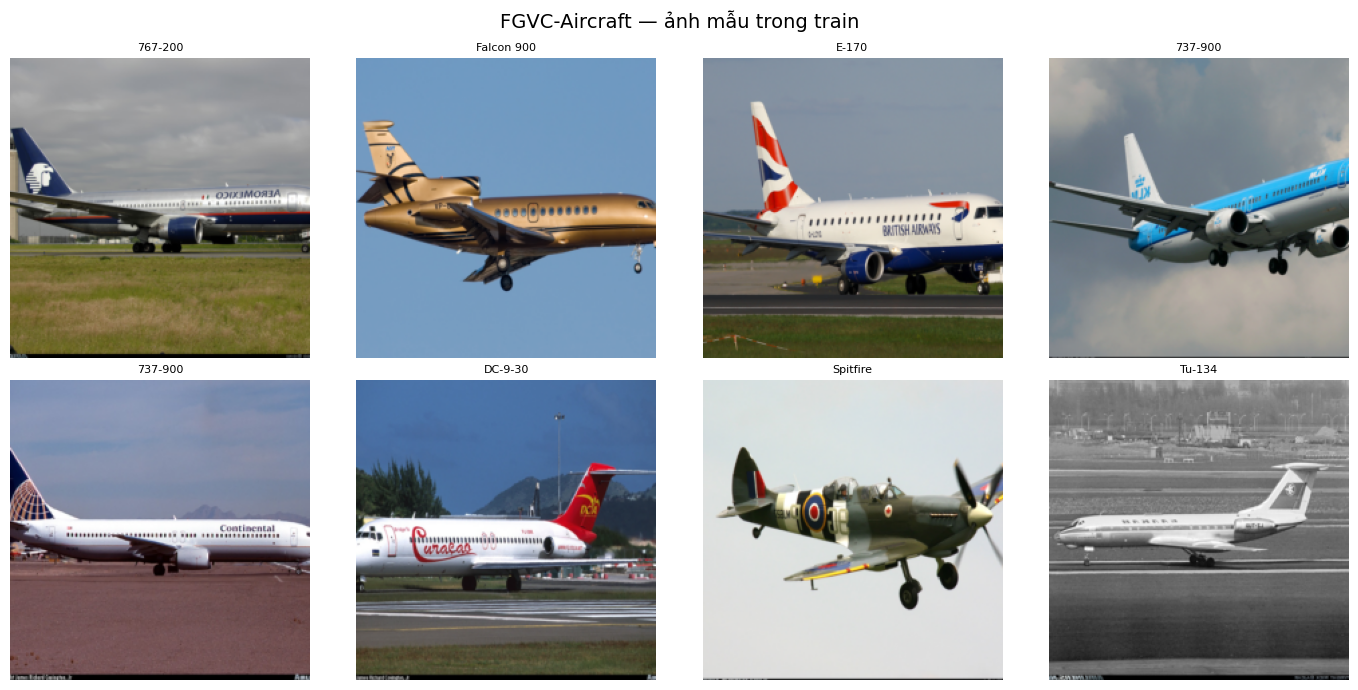

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
preview_images, preview_labels = next(iter(aircraft_train_loader))
mean = torch.tensor(AIRCRAFT_MEAN).view(3, 1, 1)
std = torch.tensor(AIRCRAFT_STD).view(3, 1, 1)
for ax, image, label in zip(axes.flat, preview_images[:8], preview_labels[:8]):
    image = (image.cpu() * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(aircraft_classes[int(label)], fontsize=8)
    ax.axis('off')
fig.suptitle('FGVC-Aircraft — ảnh mẫu trong train', fontsize=14)
plt.tight_layout(); plt.show()


#### 13.2. Tạo mô hình EfficientNet-B0 pretrained


In [19]:
aircraft_model = models.efficientnet_b0(weights=AIRCRAFT_WEIGHTS)
aircraft_in_features = aircraft_model.classifier[1].in_features
aircraft_model.classifier[1] = nn.Linear(aircraft_in_features, AIRCRAFT_NUM_CLASSES)
aircraft_model = aircraft_model.to(AIRCRAFT_DEVICE)

# Fine-tune hai block cuối và classifier; đóng băng phần đầu của backbone để giảm thời gian.
for parameter in aircraft_model.features.parameters():
    parameter.requires_grad = False
for block in aircraft_model.features[-2:]:
    for parameter in block.parameters():
        parameter.requires_grad = True

aircraft_criterion = nn.CrossEntropyLoss()
aircraft_optimizer = torch.optim.AdamW([
    {'params': [p for p in aircraft_model.features.parameters() if p.requires_grad], 'lr': 1e-4},
    {'params': aircraft_model.classifier.parameters(), 'lr': 1e-3},
], weight_decay=1e-4)
aircraft_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(aircraft_optimizer, mode='min', factor=0.5, patience=1)
aircraft_scaler = torch.cuda.amp.GradScaler(enabled=(AIRCRAFT_DEVICE.type == 'cuda'))
print('Tổng tham số:', f'{sum(p.numel() for p in aircraft_model.parameters()):,}')
print('Tham số trainable:', f'{sum(p.numel() for p in aircraft_model.parameters() if p.requires_grad):,}')
print('Đóng băng phần đầu; fine-tune hai block cuối và classifier.')


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 169MB/s]

Tổng tham số: 4,135,648
Tham số trainable: 1,257,492
Đóng băng phần đầu; fine-tune hai block cuối và classifier.



/tmp/ipykernel_582/3982774759.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  aircraft_scaler = torch.cuda.amp.GradScaler(enabled=(AIRCRAFT_DEVICE.type == 'cuda'))


Hàm dưới đây dùng mixed precision trên GPU, fine-tune hai block cuối và classifier; các block đã đóng băng giữ BatchNorm ở chế độ eval. Trong lúc train dùng augmentation; validation/test luôn dùng preprocessing cố định của pretrained weights.


In [20]:
def aircraft_run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        # Không cập nhật BatchNorm statistics của những block đã đóng băng.
        for block in model.features[:-2]:
            block.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    targets_all, preds_all = [], []
    grad_context = torch.enable_grad() if is_train else torch.inference_mode()
    with grad_context:
        for images, targets in loader:
            images = images.to(AIRCRAFT_DEVICE, non_blocking=True)
            targets = targets.to(AIRCRAFT_DEVICE, non_blocking=True)
            if is_train: optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=AIRCRAFT_DEVICE.type, dtype=torch.float16,
                                enabled=(AIRCRAFT_DEVICE.type == 'cuda')):
                logits = model(images)
                loss = aircraft_criterion(logits, targets)
            if is_train:
                aircraft_scaler.scale(loss).backward()
                aircraft_scaler.step(optimizer)
                aircraft_scaler.update()
            n = targets.size(0)
            total += n
            total_loss += loss.item() * n
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == targets).sum().item()
            targets_all.extend(targets.cpu().tolist())
            preds_all.extend(predictions.cpu().tolist())
    return {'loss': total_loss / total, 'accuracy': total_correct / total,
            'macro_f1': f1_score(targets_all, preds_all, average='macro', zero_division=0),
            'targets': targets_all, 'preds': preds_all}

aircraft_history = []
aircraft_best_loss = float('inf')
aircraft_best_state = None
aircraft_best_epoch = 0
aircraft_stale = 0
aircraft_start = time.time()
for epoch in range(1, AIRCRAFT_EPOCHS + 1):
    tr = aircraft_run_epoch(aircraft_model, aircraft_train_loader, aircraft_optimizer)
    va = aircraft_run_epoch(aircraft_model, aircraft_val_loader)
    aircraft_scheduler.step(va['loss'])
    aircraft_history.append({'epoch': epoch, 'train_loss': tr['loss'], 'train_accuracy': tr['accuracy'],
                             'val_loss': va['loss'], 'val_accuracy': va['accuracy'], 'val_macro_f1': va['macro_f1']})
    print(f"Epoch {epoch:02d}/{AIRCRAFT_EPOCHS} | train loss={tr['loss']:.4f}, acc={tr['accuracy']:.2%} | val loss={va['loss']:.4f}, acc={va['accuracy']:.2%}, macro-F1={va['macro_f1']:.4f}")
    if va['loss'] < aircraft_best_loss:
        aircraft_best_loss = va['loss']
        aircraft_best_state = copy.deepcopy(aircraft_model.state_dict())
        aircraft_best_epoch = epoch
        aircraft_stale = 0
        torch.save({'model_state_dict': aircraft_best_state, 'classes': aircraft_classes,
                    'best_epoch': epoch, 'val_loss': aircraft_best_loss},
                   AIRCRAFT_OUTPUT_DIR / 'efficientnet_b0_fgvc_aircraft_best.pth')
    else:
        aircraft_stale += 1
        if aircraft_stale >= AIRCRAFT_PATIENCE:
            print('Early stopping theo validation loss.')
            break
aircraft_model.load_state_dict(aircraft_best_state)
print(f'Checkpoint tốt nhất: epoch {aircraft_best_epoch}, val loss={aircraft_best_loss:.4f}')
print(f'Thời gian huấn luyện: {(time.time()-aircraft_start)/60:.1f} phút')


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 01/8 | train loss=3.8966, acc=15.18% | val loss=3.1944, acc=27.99%, macro-F1=0.2606
Epoch 02/8 | train loss=2.3398, acc=49.19% | val loss=2.6215, acc=35.04%, macro-F1=0.3280
Epoch 03/8 | train loss=1.6023, acc=63.50% | val loss=2.3741, acc=36.93%, macro-F1=0.3590
Epoch 04/8 | train loss=1.1331, acc=76.06% | val loss=2.1994, acc=41.85%, macro-F1=0.4118
Epoch 05/8 | train loss=0.8392, acc=82.69% | val loss=2.1234, acc=43.41%, macro-F1=0.4303
Epoch 06/8 | train loss=0.6247, acc=88.09% | val loss=2.0889, acc=43.95%, macro-F1=0.4363
Epoch 07/8 | train loss=0.4814, acc=91.60% | val loss=2.0849, acc=44.43%, macro-F1=0.4436
Epoch 08/8 | train loss=0.3775, acc=94.36% | val loss=2.0718, acc=45.57%, macro-F1=0.4520
Checkpoint tốt nhất: epoch 8, val loss=2.0718
Thời gian huấn luyện: 13.3 phút


#### 13.3. Biểu đồ quá trình huấn luyện


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1
0,1,3.896595,0.151770,3.194365,0.279928,0.260555
1,2,2.339808,0.491902,2.621547,0.350435,0.328005
2,3,1.602262,0.634973,2.374051,0.369337,0.359050
3,4,1.133097,0.760648,2.199444,0.418542,0.411784
4,5,0.839153,0.826935,2.123389,0.434143,0.430261
5,6,0.624710,0.880924,2.088877,0.439544,0.436291
6,7,0.481404,0.916017,2.084877,0.444344,0.443626
7,8,0.377548,0.943611,2.071761,0.455746,0.452004


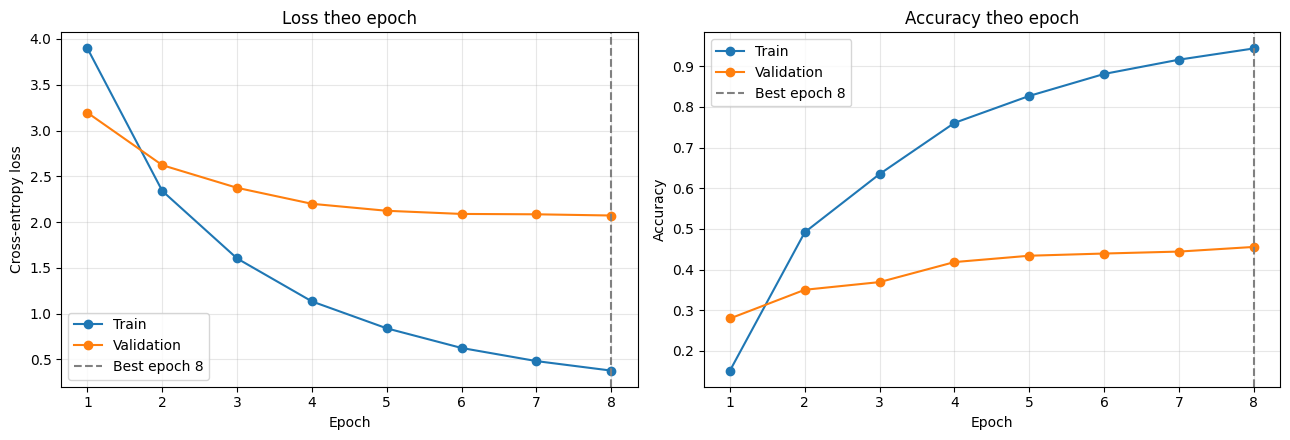

In [21]:
aircraft_history_df = pd.DataFrame(aircraft_history)
display(aircraft_history_df)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(aircraft_history_df['epoch'], aircraft_history_df['train_loss'], marker='o', label='Train')
axes[0].plot(aircraft_history_df['epoch'], aircraft_history_df['val_loss'], marker='o', label='Validation')
axes[0].axvline(aircraft_best_epoch, color='gray', linestyle='--', label=f'Best epoch {aircraft_best_epoch}')
axes[0].set(title='Loss theo epoch', xlabel='Epoch', ylabel='Cross-entropy loss'); axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(aircraft_history_df['epoch'], aircraft_history_df['train_accuracy'], marker='o', label='Train')
axes[1].plot(aircraft_history_df['epoch'], aircraft_history_df['val_accuracy'], marker='o', label='Validation')
axes[1].axvline(aircraft_best_epoch, color='gray', linestyle='--', label=f'Best epoch {aircraft_best_epoch}')
axes[1].set(title='Accuracy theo epoch', xlabel='Epoch', ylabel='Accuracy'); axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()


Đường validation được dùng để chọn checkpoint. Nếu train tiếp tục cải thiện trong khi validation dừng cải thiện hoặc suy giảm, đó là dấu hiệu có thể overfit.


#### 13.4. Đánh giá test và biểu đồ kết quả


In [22]:
aircraft_test_metrics = aircraft_run_epoch(aircraft_model, aircraft_test_loader)
print(f"Test loss: {aircraft_test_metrics['loss']:.4f}")
print(f"Test accuracy: {aircraft_test_metrics['accuracy']:.2%}")
print(f"Test macro-F1: {aircraft_test_metrics['macro_f1']:.4f}")

# Không in 100 dòng dày đặc; chỉ hiển thị 10 lớp có F1 thấp nhất để tiện xem.
aircraft_report = classification_report(
    aircraft_test_metrics['targets'], aircraft_test_metrics['preds'],
    labels=list(range(AIRCRAFT_NUM_CLASSES)), target_names=aircraft_classes,
    zero_division=0, output_dict=True
)
aircraft_report_df = pd.DataFrame(
    [aircraft_report[name] for name in aircraft_classes], index=aircraft_classes
)
print('10 biến thể có F1 thấp nhất:')
display(aircraft_report_df[['precision', 'recall', 'f1-score', 'support']]
        .sort_values('f1-score').head(10).round(3))


Test loss: 2.1058
Test accuracy: 44.70%
Test macro-F1: 0.4468
10 biến thể có F1 thấp nhất:


,precision,recall,f1-score,support
737-300,0.000,0.000,0.000,33.0
757-200,0.000,0.000,0.000,34.0
767-300,0.090,0.206,0.125,34.0
Fokker 100,0.190,0.121,0.148,33.0
737-400,0.147,0.152,0.149,33.0
747-400,0.308,0.121,0.174,33.0
DC-8,0.171,0.182,0.176,33.0
A340-300,0.114,0.424,0.179,33.0
A320,0.132,0.303,0.183,33.0
DC-9-30,0.263,0.147,0.189,34.0


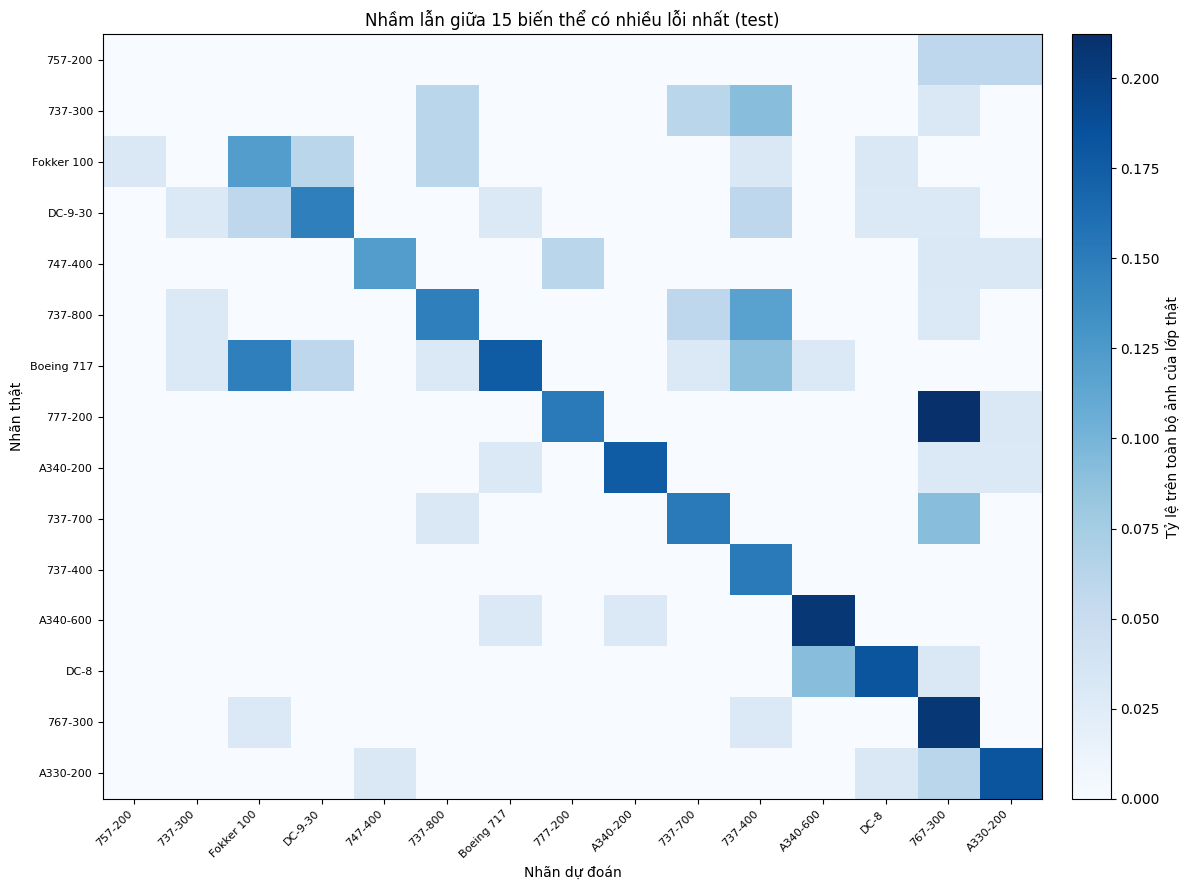

In [23]:
aircraft_cm_counts = confusion_matrix(
    aircraft_test_metrics['targets'], aircraft_test_metrics['preds'],
    labels=list(range(AIRCRAFT_NUM_CLASSES))
)
aircraft_class_errors = aircraft_cm_counts.sum(axis=1) - np.diag(aircraft_cm_counts)
aircraft_focus = np.argsort(aircraft_class_errors)[-15:][::-1]
aircraft_cm_norm = aircraft_cm_counts / np.maximum(aircraft_cm_counts.sum(axis=1, keepdims=True), 1)
aircraft_cm_focus = aircraft_cm_norm[np.ix_(aircraft_focus, aircraft_focus)]
focus_names = [aircraft_classes[i] for i in aircraft_focus]

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(aircraft_cm_focus, cmap='Blues', vmin=0,
               vmax=max(aircraft_cm_focus.max(), 0.01), aspect='auto')
ax.set_title('Nhầm lẫn giữa 15 biến thể có nhiều lỗi nhất (test)')
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thật')
ticks = np.arange(len(focus_names))
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.set_xticklabels(focus_names, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(focus_names, fontsize=8)
fig.colorbar(im, ax=ax, fraction=.04, pad=.03, label='Tỷ lệ trên toàn bộ ảnh của lớp thật')
plt.tight_layout(); plt.show()


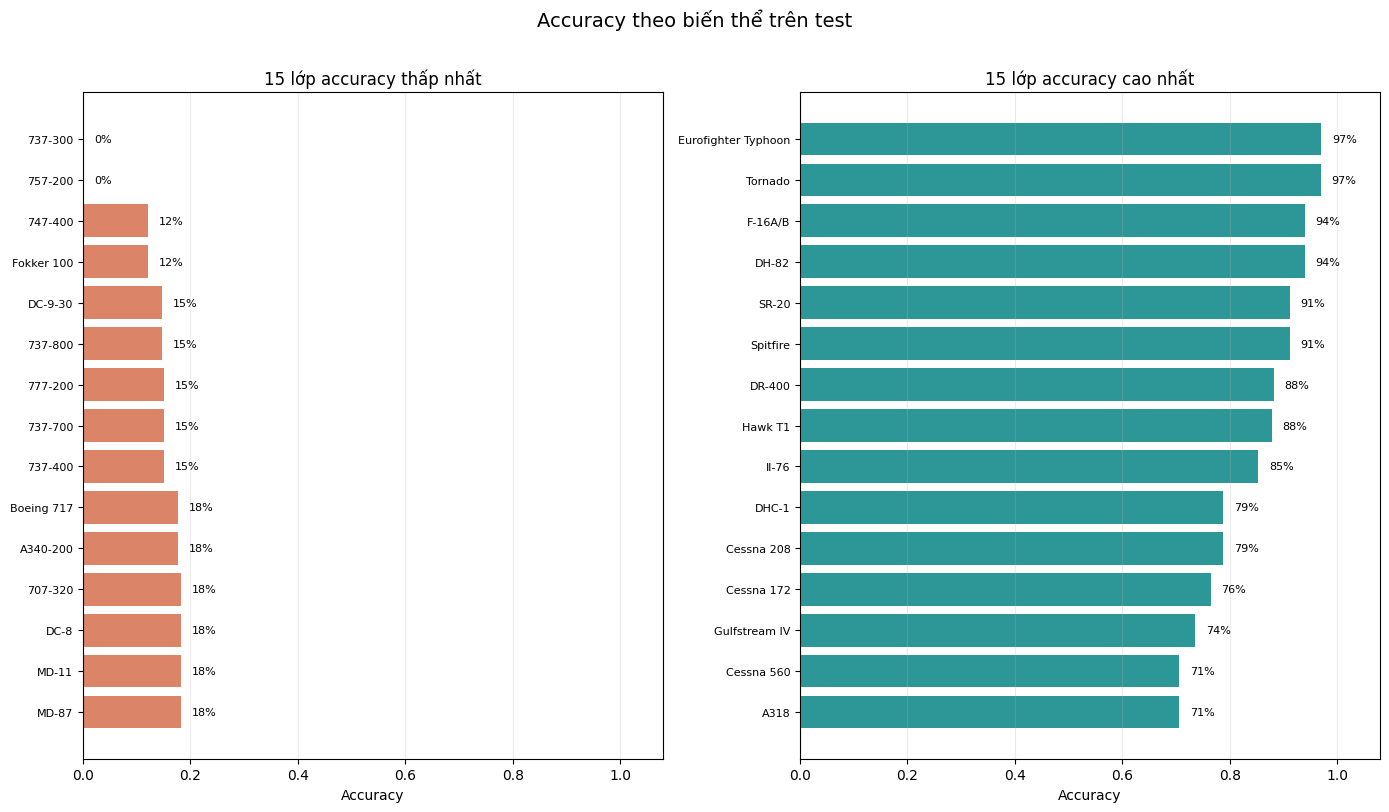

In [24]:
aircraft_support = np.bincount(aircraft_test_metrics['targets'], minlength=AIRCRAFT_NUM_CLASSES)
aircraft_correct = np.bincount(
    aircraft_test_metrics['targets'],
    weights=(np.array(aircraft_test_metrics['targets']) == np.array(aircraft_test_metrics['preds'])),
    minlength=AIRCRAFT_NUM_CLASSES
)
aircraft_class_acc = np.divide(aircraft_correct, aircraft_support,
                               out=np.zeros(AIRCRAFT_NUM_CLASSES, dtype=float),
                               where=aircraft_support > 0)
aircraft_order = np.argsort(aircraft_class_acc)
aircraft_low = aircraft_order[:15]
aircraft_high = aircraft_order[-15:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharex=True)
for ax, ids, title, color in [
    (axes[0], aircraft_low, '15 lớp accuracy thấp nhất', '#d97757'),
    (axes[1], aircraft_high, '15 lớp accuracy cao nhất', '#168c8c'),
]:
    vals = aircraft_class_acc[ids]
    names = [aircraft_classes[i] for i in ids]
    bars = ax.barh(names, vals, color=color, alpha=.9)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel('Accuracy')
    ax.grid(axis='x', alpha=.25)
    ax.tick_params(axis='y', labelsize=8)
    for bar, value in zip(bars, vals):
        ax.text(min(value + .02, 1.01), bar.get_y() + bar.get_height()/2,
                f'{value:.0%}', va='center', fontsize=8)
fig.suptitle('Accuracy theo biến thể trên test', y=1.01, fontsize=14)
plt.tight_layout(); plt.show()


Các biểu đồ đã giới hạn nhãn để dễ đọc: confusion matrix chỉ hiển thị 15 lớp có nhiều lỗi nhất; biểu đồ accuracy tách 15 lớp thấp nhất và cao nhất. Bảng F1 cũng chỉ hiện 10 lớp thấp nhất. Các chỉ số phản ánh lần chạy hiện tại, không phải kết luận thống kê.
